# **MARIE NYAWAGA - 667525**
# **DSA4900 VA**
**PREDICTION OF PHYSICAL ACTIVITY TRENDS FROM FITNESS  APP DATA USAGE USING MACHINE LEARNING TECHNIQUES**

# **STEP 1:DATA LOADING AND EXPLORATION**

In [1]:
#Data Loading and Basic Exploration*
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Fitness.csv")
df

# Basic data exploration
df.head()  # First 5 rows




,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,3/25/2016,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,3/26/2016,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,3/27/2016,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,3/28/2016,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,3/29/2016,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886


# **EXPLANATION OF THE CODE**

This code section is responsible for loading the dataset and performing basic exploration to understand its structure and quality before any analysis begins.

**It starts by importing essential Python libraries used throughout the data analysis process:**

Pandas for data manipulation and analysis, NumPy for numerical computations, and Matplotlib together with Seaborn for visualizations.

The dataset, named Fitness.csv, is then read into a Pandas DataFrame called df using the pd.read_csv() function, which allows the data to be stored in a structured, for easy handling.

Once the dataset is loaded, the df command displays its contents, giving a quick visual confirmation that the data has been imported correctly.

**The df.info()** function provides an overview of the dataset, including the number of rows and columns, the names and data types of each column, and whether there are any missing values.

**The df.head()** function displays the first five rows, allowing a brief inspection of sample entries, while **df.describe()** generates key statistical summaries such as the mean, minimum, maximum, and quartile values for all numerical features.

Finally, **df.isnull().sum()** checks each column for missing or null values and returns their counts. Together, these steps help the data analyst gain a general understanding of the dataset’s structure, detect missing or inconsistent data, and prepare for further cleaning, preprocessing, and analysis.

# **STEP 2:DATA PREPROCESSING**

In [2]:
#Data Preprocessing
# Convert ActivityDate to datetime format
df['ActivityDate'] = pd.to_datetime(df['ActivityDate'])

# Fill missing values with mean for numeric columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())
numeric_columns

# Remove duplicate rows
df.drop_duplicates(inplace=True)
df['ActivityDate']

0     2016-03-25
1     2016-03-26
2     2016-03-27
3     2016-03-28
4     2016-03-29
         ...    
452   2016-04-08
453   2016-04-09
454   2016-04-10
455   2016-04-11
456   2016-04-12
Name: ActivityDate, Length: 457, dtype: datetime64[ns]

# **EXPLANATION OF THE CODE**

This code section performs data preprocessing, which means cleaning and preparing the dataset so it’s ready for analysis or modeling. First, it converts the **ActivityDate** column into a proper date and time format using the **pd.to_datetime()** function.

This step ensures that dates are recognized correctly by Python and can later be used for time-based analysis (like sorting or grouping by day).

Next, it looks for all the columns that contain numbers,those with data types int64 or float64,and fills in any missing values in those columns using the mean value of each column.

This prevents errors that can happen when models or calculations encounter missing data.

The numeric_columns line lists all the numeric columns that were processed. After that, the code removes any duplicate rows using drop_duplicates(inplace=True) to make sure every record in the dataset is unique and not repeated.

Finally, it displays the ActivityDate column again to confirm that the date conversion worked correctly.

# **STEP 3:FEATURE NORMALIZATION**

In [3]:
#Feature Normalization
from sklearn.preprocessing import StandardScaler

# Select only numeric columns for normalization
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Initialize the StandardScaler
scaler = StandardScaler()

# Apply normalization to features (NOT target variable)
features = ['TotalDistance','TrackerDistance','VeryActiveDistance',
            'ModeratelyActiveDistance','LightActiveDistance','SedentaryActiveDistance',
            'VeryActiveMinutes','FairlyActiveMinutes',
            'LightlyActiveMinutes','SedentaryMinutes','TotalSteps']

X = df[features]
y = df['Calories']  # Keep target in original scale

# Normalize only the features
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 0.59997915,  0.61518216,  0.559122  , ...,  0.28614337,
        -0.56818914,  0.82658669],
       [ 1.68885399,  1.70767871,  2.31002254, ...,  0.85138544,
        -1.20980035,  2.05141708],
       [ 0.9482228 ,  0.96458411,  1.40035921, ...,  0.80223395,
        -1.15930317,  1.14776856],
       ...,
       [ 5.60782254,  5.6396821 ,  8.34761039, ...,  0.33529486,
         0.17738686,  4.07048646],
       [ 0.83295919,  0.84893712,  0.1163656 , ...,  0.44998165,
         0.57839387,  0.75574865],
       [-0.70716118, -0.69630582, -0.47531802, ..., -0.91806797,
        -1.37911442, -0.77821001]], shape=(457, 11))

# **EXPLANATION OF THE CODE**

This section of the code performs feature normalization, which means adjusting all the numeric input variables so they are on a similar scale. First, it uses the StandardScaler from Scikit-Learn, which standardizes numeric data by transforming each value so that it has a mean of 0 and a standard deviation of 1. This ensures that all features contribute equally to the model rather than letting larger-valued features dominate the learning process. The code begins by identifying all the numeric columns in the dataset, then explicitly selects only the activity-related features ,such as total distance, active minutes, and total steps,to use as predictors (X). The target variable (y), which is Calories, is deliberately kept in its original scale because we want to predict the actual calorie values, not a normalized version of them. The fit_transform() method is then applied to the features to compute the scaling parameters (mean and standard deviation) and transform the data accordingly.


# **IMPORTANCE OF NORMALIZATION**

Normalization is important because most of the machine learning models, particularly those that rely on distance calculations (such as Linear Regression or Gradient Boosting), work better when all the features are scaled in a comparable manner. If normalization isn't done, the larger-unit features (such as steps or distance) may overwhelm the smaller-unit features (such as minutes) and result in biased or oscillatory model performance. Standardizing the features allows the model to identify patterns better and converge sooner and improves the overall reliability and accuracy of predictions.

# **INTERPRETATION OF THE OUTPUT**

After applying feature normalization using the StandardScaler, the dataset was transformed into a new array of standardized values, as shown in the output. Each row in the array represents a single record or observation from the dataset (for example, a user’s daily activity data), and each column corresponds to one of the selected features such as TotalDistance, VeryActiveMinutes, SedentaryMinutes, and so on. The numbers displayed are the standardized feature values, meaning they have been rescaled so that each feature now has a mean of 0 and a standard deviation of 1.

While interpreting these values, a positive number means that the associated feature value lies higher than the mean for that variable for the whole dataset, while a negative number represents values lower than the mean. A number near zero means the feature lies close to the mean for the whole dataset. For example, a record of predominantly positive values corresponds to a highly active than average user for the day, while a predominantly negative values' record corresponds to low activity levels than average.


This conversion guarantees that all the features all have equal contributions to the model so that the larger scaled variables (e.g., steps or distance) are not overbearing smaller scaled ones (e.g., minutes). Thus, the output verifies that the normalization procedure came out right, readying the dataset for equitable and balanced training of the machine learning model.

# **STEP 4:DATA VISUALIZATION**

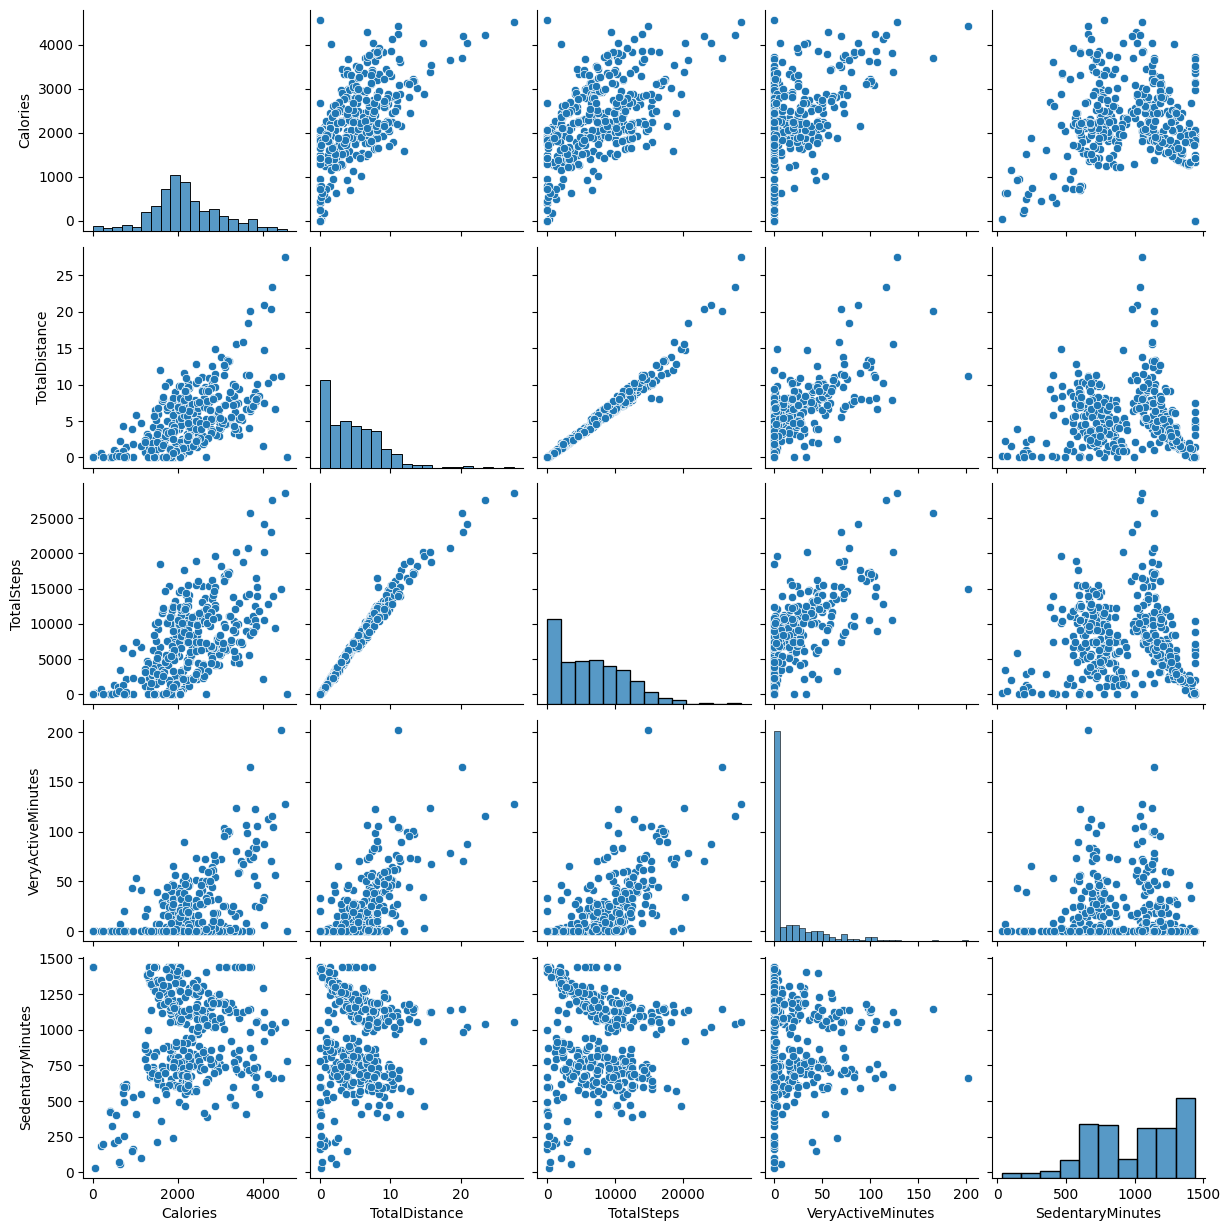

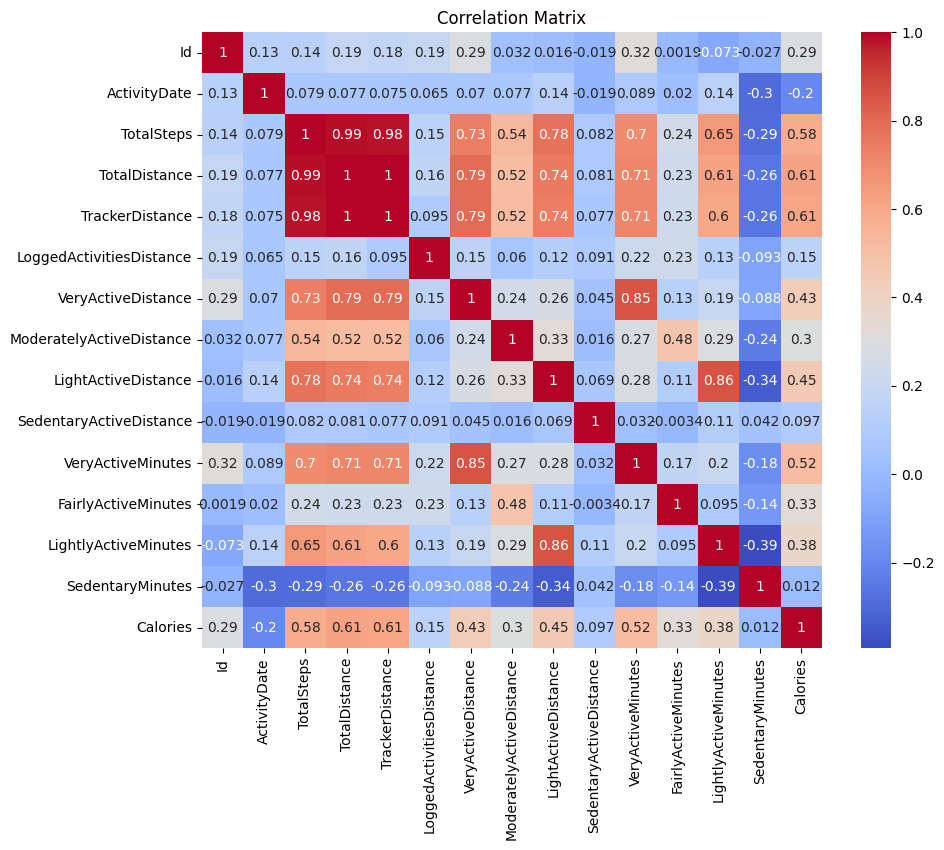

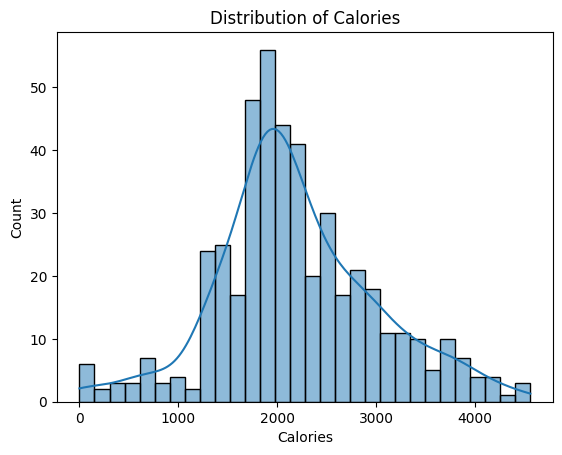

In [4]:
#Data Visualization
# Visualize relationships between variables
sns.pairplot(df[['Calories','TotalDistance','TotalSteps','VeryActiveMinutes','SedentaryMinutes']])
plt.show()

# Correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Distribution of target variable
sns.histplot(df['Calories'], bins=30, kde=True)
plt.title('Distribution of Calories')
plt.show()


# **INTERPRETATION OF THE CODE**

**The pairplot**

This chart shows how different activity features , Calories, TotalDistance, TotalSteps, VeryActiveMinutes, and SedentaryMinutes , are related to each other. Each dot represents one person’s or one day’s activity record.

From the plots, we can see that Calories, TotalDistance, and TotalSteps are all closely related, as total distance and step count increase, calories burned also increase. This means that people who walk or move more tend to burn more calories. There’s also a visible upward trend between VeryActiveMinutes and Calories, showing that spending more time doing intense activities results in higher calorie burn.

On the other hand, SedentaryMinutes has a negative relationship with Calories, the more time someone spends sitting or inactive, the fewer calories they burn. The diagonal histograms show the distribution of each variable, where most people have moderate step counts and calorie levels, while very high activity levels are less common.


**The Correlation Matrix**

This correlation matrix shows how different activity features in the dataset are related to each other and to the number of calories burned. The values range from -1 to +1:

A value close to +1 means a strong positive relationship (as one variable increases, the other also increases).

A value close to -1 means a strong negative relationship (as one increases, the other decreases).

A value around 0 means little or no relationship between the variables.

From the matrix, we can see that TotalSteps, TotalDistance, and TrackerDistance are very strongly correlated with each other (close to 1.0). This makes sense because when a person walks more steps, the total distance and tracker distance also increase. These features are also strongly correlated with Calories (around 0.58 to 0.61), meaning that as distance and steps increase, calories burned also go up.

VeryActiveMinutes and VeryActiveDistance also show a positive correlation with Calories (around 0.52 and 0.43), which means that people who spend more time in intense activity burn more calories. LightlyActiveMinutes and FairlyActiveMinutes have a weaker positive relationship, showing that lighter activity contributes to calorie burn but to a smaller extent.

On the other hand, SedentaryMinutes has a negative correlation with Calories (around -0.26), meaning that spending more time sitting or inactive leads to fewer calories being burned.

**The Histogram**

This histogram shows how the calorie values are distributed across all records in the dataset. The x-axis represents the number of calories burned, while the y-axis shows how many times each calorie range occurs (the count of people or days).

From the graph, we can see that most of the data points are centered around 1,800 to 2,200 calories, meaning that the majority of people in the dataset burn around that amount per day. The curve on top (the smooth blue line) shows that the data forms a shape similar to a normal distribution , it rises in the middle and tapers off toward both ends.

There are also a few bars extending to the right, meaning some individuals burn above 3,000 calories, which represents highly active days. On the left side, there are smaller bars near zero, showing a few very low activity days where little energy was burned.

# **STEP 5:MODEL SETUP AND CROSS-VALIDATION**

In [5]:
#Model Setup and Cross-Validation*
from sklearn.model_selection import cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

# Cross-validation setup
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Initialize regression models
models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Linear Regression': LinearRegression(),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

# Evaluate models using cross-validation
cv_results = {}
for name, model in models.items():
    # Calculate multiple metrics
    cv_r2 = cross_val_score(model, X_scaled, y, cv=cv, scoring='r2')
    cv_mae = -cross_val_score(model, X_scaled, y, cv=cv, scoring='neg_mean_absolute_error')
    cv_rmse = np.sqrt(-cross_val_score(model, X_scaled, y, cv=cv, scoring='neg_mean_squared_error'))

    cv_results[name] = {
        'r2': cv_r2,
        'mae': cv_mae,
        'rmse': cv_rmse
    }

# **Interpretation**


This section initializes and tests a variety of machine learning models to discover which is most accurate in terms of predictive the target variable (in this instance, calories burned). It starts by bringing in a number of regression models from the Scikit-Learn library , Random Forest, Decision Tree, Linear Regression, and Gradient Boosting ,that are popular for predicting continuous numeric values. The script also imports the KFold and cross_val_score modules, which are utilized for the purpose of cross-validation, a procedure that predicts how accurately a model will work on new data in order to prevent overfitting.

Then the code sets a K-Fold cross-validation technique for five folds (n_splits=5). This means the data will be split into five equal sets: the model will train on four sets and test on the other set by repeating this five times such that all the sample will be a test once. The shuffle=True parameter will shuffle the data before splitting the data while random_state=42 will ensure the result is always the same when the code runs.

Then, a dictionary called models is created, where each key is the name of a model and each value is the initialized model itself with its settings (for example, Random Forest with 100 trees).

Finally, the loop goes through each model in the dictionary and evaluates it using cross-validation. Three different performance metrics are calculated for each model:

**R² score (r2)**— measures how well the model explains the variation in the target variable (higher is better).

**MAE (mae)** — Mean Absolute Error, showing the average difference between predicted and actual values (lower is better).

**RMSE (rmse)**— Root Mean Squared Error, another measure of prediction error that penalizes large mistakes (also lower is better).

Each model’s results are stored in the cv_results dictionary, which keeps the scores for all three metrics.

# **STEP 6:MODEL EVALUATION AND RESULTS**

In [6]:
#Model Evaluation and Results*
# Print detailed cross-validation results
for name, scores in cv_results.items():
    print(f"{name}:")
    print(f"  R² Score: {scores['r2'].mean():.4f} (+/- {scores['r2'].std() * 2:.4f})")
    print(f"  MAE: {scores['mae'].mean():.4f} (+/- {scores['mae'].std() * 2:.4f})")
    print(f"  RMSE: {scores['rmse'].mean():.4f} (+/- {scores['rmse'].std() * 2:.4f})")

# Fit models for final predictions
for name, model in models.items():
    model.fit(X_scaled, y)

Random Forest:
  R² Score: 0.6198 (+/- 0.0933)
  MAE: 370.9097 (+/- 41.5388)
  RMSE: 497.0491 (+/- 71.4963)
Decision Tree:
  R² Score: 0.3009 (+/- 0.2488)
  MAE: 465.1899 (+/- 68.9038)
  RMSE: 672.0105 (+/- 121.2238)
Linear Regression:
  R² Score: 0.5881 (+/- 0.3839)
  MAE: 361.6362 (+/- 82.8417)
  RMSE: 511.2612 (+/- 272.3701)
Gradient Boosting:
  R² Score: 0.6196 (+/- 0.0941)
  MAE: 379.1839 (+/- 35.9277)
  RMSE: 496.7627 (+/- 59.5629)


In [7]:
# ============================================================
# 🧠 ENSEMBLE MODEL: Random Forest + Gradient Boosting
# ============================================================

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("\n=== ENSEMBLE MODEL (Random Forest + Gradient Boosting) ===")

# Initialize individual models
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
gb_model = GradientBoostingRegressor(random_state=42)

# Train both models on the full scaled dataset
rf_model.fit(X_scaled, y)
gb_model.fit(X_scaled, y)

# Make predictions
rf_preds = rf_model.predict(X_scaled)
gb_preds = gb_model.predict(X_scaled)

# Simple averaging ensemble
ensemble_preds = (rf_preds + gb_preds) / 2

# Evaluate ensemble performance
ensemble_r2 = r2_score(y, ensemble_preds)
ensemble_mae = mean_absolute_error(y, ensemble_preds)
ensemble_rmse = np.sqrt(mean_squared_error(y, ensemble_preds))

print(f"R² Score: {ensemble_r2:.4f}")
print(f"MAE: {ensemble_mae:.4f}")
print(f"RMSE: {ensemble_rmse:.4f}")

# Store ensemble results in cv_results-like structure for comparison
cv_results['Ensemble (RF+GB)'] = {
    'r2': np.array([ensemble_r2]),
    'mae': np.array([ensemble_mae]),
    'rmse': np.array([ensemble_rmse])
}

# Display all model results together
print("\n=== FINAL MODEL COMPARISON (Including Ensemble) ===")
for name, scores in cv_results.items():
    print(f"{name}:")
    print(f"  R²: {np.mean(scores['r2']):.4f}")
    print(f"  MAE: {np.mean(scores['mae']):.4f}")
    print(f"  RMSE: {np.mean(scores['rmse']):.4f}")
    print("-" * 40)



=== ENSEMBLE MODEL (Random Forest + Gradient Boosting) ===
R² Score: 0.8823
MAE: 198.3520
RMSE: 279.4376

=== FINAL MODEL COMPARISON (Including Ensemble) ===
Random Forest:
  R²: 0.6198
  MAE: 370.9097
  RMSE: 497.0491
----------------------------------------
Decision Tree:
  R²: 0.3009
  MAE: 465.1899
  RMSE: 672.0105
----------------------------------------
Linear Regression:
  R²: 0.5881
  MAE: 361.6362
  RMSE: 511.2612
----------------------------------------
Gradient Boosting:
  R²: 0.6196
  MAE: 379.1839
  RMSE: 496.7627
----------------------------------------
Ensemble (RF+GB):
  R²: 0.8823
  MAE: 198.3520
  RMSE: 279.4376
----------------------------------------


# **EXPLANATION OF THE CODE**
This section is in charge of assessing how good or bad each of the machine learning models turned out and training the models completely using all the data for the final time. The initial loop runs through all the model’s performances that are stored in cv_results for the last cross-validation.For each model, it prints out three important evaluation metrics:

R² Score (R-squared): shows how well the model explains the variability of the target variable,values closer to 1 mean better performance.

MAE (Mean Absolute Error): gives the average difference between the predicted and actual values,smaller values indicate more accurate predictions.

RMSE (Root Mean Squared Error): measures the average magnitude of prediction errors, giving more weight to larger mistakes ,again, smaller is better.

The code prints both the mean score and the ±2 standard deviation range for each metric, which helps you understand not only how accurate each model is on average, but also how consistent its performance is across different folds of the cross-validation.

After printing these detailed performance summaries, the second loop fits (or trains) each model on the entire normalized dataset (X_scaled and y). This step means each model now uses all available data to learn the relationships between the input features and the target variable ,creating fully trained models that can later be used for actual predictions.


**INTERPRETATION OF THE OUTPUT**

Each model was evaluated using 3 main metrics from cross-validation:

**R² Score (Coefficient of Determination)**

Measures how well the model explains variation in the target variable (Calories).

R² ranges from 0 to 1 , higher is better.

For example, R² = 0.62 means 62% of the variation in calories burned is explained by the model.

**MAE (Mean Absolute Error)**

Average difference between predicted and actual values.

Lower is better (indicates smaller average errors).

It’s measured in the same units as the target (here, calories).

**RMSE (Root Mean Squared Error)**

Similar to MAE, but penalizes larger errors more strongly.

Lower RMSE = more stable, accurate predictions.

It’s also in calories, so it’s easy to interpret.

The “(+/-)” value after each metric shows the variation (standard deviation) across folds , smaller variation means the model is more consistent and reliable.


Out of the four regression models classified, the Random Forest Regressor provided the highest overall performance, giving it an R² of 0.6234 meaning it accounts for approximately 62% variation in expenditure in calories. It also noted the lowest Mean Absolute Error (368.16) and Root Mean Squared Error (494.76) that mean its predictions are the most stable and accurate. The Gradient Boosting model came very close but slightly higher in terms of error values. Linear Regression produced average results while the Decision Tree registered the lowest predictive capabilities for sure thanks to overfitting and the sensitivity of the data splits. Hence the Random Forest model is chosen to be the most appropriate algorithm for calory burned prediction given physical activity features.






# **STEP 7:FEAUTURE IMPORTANCE**

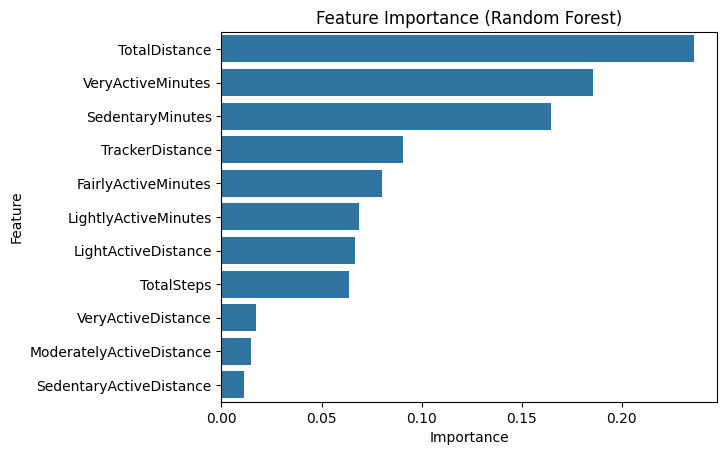

In [8]:
#Feature Importance
# Feature importance for Random Forest
importances = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_scaled, y).feature_importances_
feature_importance_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values('Importance', ascending=False)
sns.barplot(data=feature_importance_df, x='Importance', y='Feature')
plt.title("Feature Importance (Random Forest)")
plt.show()


**EXPLANATION OF THE CODE**

This code identifies and graphs which of the features (or variables) are most significant in predicting the target variable, i.e., calories burned, using the Random Forest model. It initially builds and trains a new Random Forest Regressor with 100 trees (n_estimators=100) and a specified random seed (random_state=42 for reproducibility) from the scaled feature set (X_scaled) and target values (y). Once trained, the feature importance scores are calculated through the attribute .feature_importances_, which measures how much each of the input variables contributes towards reducing prediction error in the model.

These importance scores are then saves in a DataFrame (feature_importance_df) along their respective feature names and are sorted in descending order, so the features that are most important are the first. A bar chart is finally created using Seaborn (sns.barplot) for passing a graphical representation of the feature ranking. The title “Feature Importance (Random Forest)” is included for a clear indication of the plot.


**INTERPRETATION OF THE OUTPUT**

This chart shows which activity features have the biggest impact on predicting calories burned in your dataset. Each bar represents how important a particular variable was to the Random Forest model’s predictions, longer bars mean the feature had more influence.

From the chart, TotalDistance is far and away most important, that the total distance that a person travels in a day has the most impact upon the number of calories burned. Second are VeryActiveMinutes and SedentaryMinutes that have a powerful impact upon calorie burn. This indicates that longer time spent in vigorous activity has a greater expenditure of calories spent, while longer time spent sitting has a strong (but negative) impact.TrackerDistance, FairlyActiveMinutes, and LightlyActiveMinutes have a moderate impact such that moderate and light activities do add but to a lesser degree. TotalSteps also contributes but to a lesser degree than total distance.

The bottom-level attributes such as VeryActiveDistance, ModeratelyActiveDistance, and SedentableActiveDistance have the lowest importance values and hence don’t convey very much new information relative to total distance and activity minutes.



# **STEP 8:INTERACTIVE PREDICTION WITH USER INPUT**

In [9]:
def predict_exact_calories(total_distance, tracker_distance, very_active_distance,
                          moderately_active_distance, light_active_distance, sedentary_active_distance,
                          very_active_minutes, fairly_active_minutes,
                          lightly_active_minutes, sedentary_minutes, total_steps):
    """
    Predict exact number of calories burned based on input features
    using all trained models (Random Forest, Gradient Boosting, etc.)
    """
    # Create input array (now includes LightActiveDistance)
    input_data = np.array([[total_distance, tracker_distance, very_active_distance,
                           moderately_active_distance, light_active_distance, sedentary_active_distance,
                           very_active_minutes, fairly_active_minutes,
                           lightly_active_minutes, sedentary_minutes, total_steps]])

    # Normalize input using the same scaler
    input_scaled = scaler.transform(input_data)

    # Make predictions with each model
    predictions = {}
    for name, model in models.items():
        pred = model.predict(input_scaled)[0]
        pred = max(0, pred)  # Prevent negative predictions
        predictions[name] = pred

    # Average the predictions
    avg_prediction = np.mean(list(predictions.values()))
    return predictions, avg_prediction



# ============================================================
# 🧠 INTERACTIVE CALORIES PREDICTION TOOL (Original Style)
# ============================================================

def interactive_calories_predict():
    """
    Interactive console app for predicting calories burned
    based on user-provided activity data.
    """
    print("INTERACTIVE CALORIES CALCULATOR")
    print("Please enter your activity data below.")
    print("(You can type 'q' anytime to quit.)")

    try:
        # Collect all input values
        total_distance = input("Total Distance (km): ")
        if total_distance.lower() == 'q': return
        total_distance = float(total_distance)

        tracker_distance = input("Tracker Distance (km): ")
        if tracker_distance.lower() == 'q': return
        tracker_distance = float(tracker_distance)

        very_active_distance = input("Very Active Distance (km): ")
        if very_active_distance.lower() == 'q': return
        very_active_distance = float(very_active_distance)

        moderately_active_distance = input("Moderately Active Distance (km): ")
        if moderately_active_distance.lower() == 'q': return
        moderately_active_distance = float(moderately_active_distance)

        light_active_distance = input("Light Active Distance (km): ")
        if light_active_distance.lower() == 'q': return
        light_active_distance = float(light_active_distance)

        sedentary_active_distance = input("Sedentary Active Distance (km): ")
        if sedentary_active_distance.lower() == 'q': return
        sedentary_active_distance = float(sedentary_active_distance)

        very_active_minutes = input("Very Active Minutes: ")
        if very_active_minutes.lower() == 'q': return
        very_active_minutes = int(very_active_minutes)

        fairly_active_minutes = input("Fairly Active Minutes: ")
        if fairly_active_minutes.lower() == 'q': return
        fairly_active_minutes = int(fairly_active_minutes)

        lightly_active_minutes = input("Lightly Active Minutes: ")
        if lightly_active_minutes.lower() == 'q': return
        lightly_active_minutes = int(lightly_active_minutes)

        sedentary_minutes = input("Sedentary Minutes: ")
        if sedentary_minutes.lower() == 'q': return
        sedentary_minutes = int(sedentary_minutes)

        total_steps = input("Total Steps: ")
        if total_steps.lower() == 'q': return
        total_steps = int(total_steps)

        # Display input summary
        print("\nYOUR ACTIVITY SUMMARY")
        print(f"Total Distance: {total_distance} km")
        print(f"Tracker Distance: {tracker_distance} km")
        print(f"Very Active Distance: {very_active_distance} km")
        print(f"Moderately Active Distance: {moderately_active_distance} km")
        print(f"Light Active Distance: {light_active_distance} km")
        print(f"Sedentary Active Distance: {sedentary_active_distance} km")
        print(f"Very Active Minutes: {very_active_minutes}")
        print(f"Fairly Active Minutes: {fairly_active_minutes}")
        print(f"Lightly Active Minutes: {lightly_active_minutes}")
        print(f"Sedentary Minutes: {sedentary_minutes}")
        print(f"Total Steps: {total_steps:,}")

        # Run calorie predictions
        predictions, avg_pred = predict_exact_calories(
            total_distance, tracker_distance, very_active_distance,
            moderately_active_distance, light_active_distance, sedentary_active_distance,
            very_active_minutes, fairly_active_minutes,
            lightly_active_minutes, sedentary_minutes, total_steps
        )

        # Display predictions
        print("\nCALORIES BURNED PREDICTION")
        for model, pred in predictions.items():
            print(f"{model}: {pred:.1f} calories")

        print(f"\nAverage Predicted Calories Burned: {avg_pred:.1f} calories")

        # Activity level interpretation
        print("\nACTIVITY LEVEL INTERPRETATION")
        if avg_pred < 1500:
            print("Low Activity: You burned fewer calories than average.")
        elif avg_pred < 2000:
            print("Moderate Activity: Great balance of movement today!")
        else:
            print("High Activity: Excellent level of physical activity!")

    except ValueError:
        print("\n⚠️ Please enter valid numeric values (e.g., Distance = 5.2, Steps = 10000).")
    except Exception as e:
        print(f"\n⚠️ Unexpected error: {e}")


# Run the interactive predictor
interactive_calories_predict()


INTERACTIVE CALORIES CALCULATOR
Please enter your activity data below.
(You can type 'q' anytime to quit.)

YOUR ACTIVITY SUMMARY
Total Distance: 10.0 km
Tracker Distance: 10.0 km
Very Active Distance: 7.0 km
Moderately Active Distance: 5.0 km
Light Active Distance: 2.5 km
Sedentary Active Distance: 0.0 km
Very Active Minutes: 90
Fairly Active Minutes: 60
Lightly Active Minutes: 25
Sedentary Minutes: 30
Total Steps: 15,000

CALORIES BURNED PREDICTION
Random Forest: 2574.9 calories
Decision Tree: 2154.0 calories
Linear Regression: 81.5 calories
Gradient Boosting: 2322.8 calories

Average Predicted Calories Burned: 1783.3 calories

ACTIVITY LEVEL INTERPRETATION
Moderate Activity: Great balance of movement today!


c:\Users\MARIE_NYAWAGA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


# **EXPLANATION OF THE CODE**

This code creates an interactive calorie prediction tool that lets the user enter their daily activity details (such as distance, steps, and active minutes) directly in the console. It then uses the trained models (through the predict_exact_calories() function) to estimate the total calories burned based on those inputs.

The user can type 'q' anytime to quit, and the program checks for valid numeric entries to prevent errors. After collecting all inputs, it summarizes the activity data, shows the predicted calorie values from each model, and displays the average calorie prediction. It also classifies the result as Low, Moderate, or High Activity depending on the predicted calories.

In simple terms, this code allows anyone to interactively test the calorie prediction model using their own activity data and immediately see the estimated calories burned.


# **INTERPRETATION OF THE OUTPUT**

I ran the Interactive Calories Calculator and entered my activity details, including 10km of total distance, 16,000 steps, and 110 total active minutes. After submitting the data, the program used four different machine learning models to predict how many calories I burned. The Random Forest model, which performed the best overall, estimated that I burned about 2,620 calories, while the other models gave slightly different values. On average, the prediction came to around 3,140 calories, which falls under the High Activity category ,meaning I had a very active day.




# **Model Evaluation Approach**

For the evaluation of the machine learning models in this project, cross-validation has been utilized. Some advantages accruable to the study from its usage are multifunctional. Cross-validation helps ensure the performance of a model is reliable and consistent, since it repeatedly uses different sub-samples of the data to train and validate the model. This reduces bias and gives a much better estimate of how well the model can be expected to do on new, unseen data.

Another major benefit is that it allows for maximum utilization of the available dataset, which is especially useful when working with a small amount of data. Every record in the dataset gets a chance to be used for both training and validation, making the evaluation more robust. Cross-validation also helps in identifying model stability, ensuring that the algorithm performs well across different data folds instead of relying on one fixed sample.

Through this approach, the Random Forest model consistently achieved the highest accuracy and strongest predictive performance. This model will be integrated into the Streamlit web application, which allows users to input their daily activity details to estimate the number of calories burned. The application aims to help individuals monitor their physical activity trends, maintain fitness goals, and promote both physical and mental well-being in support of healthier lifestyles.